# BITS Pilani - Work Integrated Learning Programmes (WILP)
## M.Tech (AIML) - Machine Learning
### Assignment 2: End-to-End Classification & Streamlit Deployment
**Dataset:** Viral Songs Dataset (Music Virality Classification)  
**Author:** WILP M.Tech AIML Student  
**Environment:** BITS Virtual Lab (VS Code / JupyterLab)  

---

### Objectives:
1. Implement and train **5 Machine Learning Classifiers**:
   - Logistic Regression
   - Decision Tree Classifier
   - K-Nearest Neighbor Classifier (KNN)
   - Naive Bayes Classifier (GaussianNB)
   - Support Vector Machine (SVM)
2. Compute **6 Required Evaluation Metrics** for all models:
   - Accuracy, ROC-AUC, Precision, Recall, F1 Score, Matthews Correlation Coefficient (MCC)
3. Generate comparison tables, confusion matrices, and ROC curves.
4. Export preprocessed artifacts, model binaries (`.joblib`), and `test_data.csv` for Streamlit app deployment.


In [1]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    roc_curve
)

# Set visual styling for BITS Lab reporting
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette(['#880e4f', '#0052FF', '#00D2FF', '#4a154b'])
print("All required packages imported successfully!")


All required packages imported successfully!


## Step 1: Dataset Loading & Exploratory Data Analysis (EDA)
Let us load the Viral Songs dataset and inspect its structure, dimensions, data types, and target distribution.


In [2]:
data_path = os.path.join("Viral_Songs_Datatset", "viral_songs.csv")
if not os.path.exists(data_path):
    data_path = "viral_songs.csv"

df = pd.read_csv(data_path)
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("\nFirst 5 Rows:")
display(df.head())


Dataset Shape: 10000 rows, 17 columns

First 5 Rows:


,track_id,track_name,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
0,track_00001,Track_00001,Artist_1519,Pop,2013,237,0.760,0.703,0.747,140.8,0.115,0.103,0.206,0.272,-9.41,661412,1
1,track_00002,Track_00002,Artist_0458,Electronic,2018,239,0.436,0.934,0.672,105.1,0.016,0.002,0.024,0.000,-9.89,1114175,1
2,track_00003,Track_00003,Artist_1386,Hip-Hop,2014,148,0.642,0.725,0.460,90.6,0.010,0.520,0.079,0.053,-5.53,105832,1
3,track_00004,Track_00004,Artist_0865,Classical,2012,216,0.326,0.456,0.299,71.3,0.966,0.042,0.000,0.074,-11.39,915397,0
4,track_00005,Track_00005,Artist_0192,Pop,2011,277,0.599,0.683,0.700,132.6,0.078,0.113,0.000,0.036,-5.56,3690733,1


In [3]:
print("Dataset Info:")
df.info()

print("\nMissing Values Check:")
print(df.isnull().sum())

print("\nTarget Distribution ('viral'):")
print(df['viral'].value_counts(normalize=True).mul(100).round(2).astype(str) + '%')


Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track_id          10000 non-null  object 
 1   track_name        10000 non-null  object 
 2   artist            10000 non-null  object 
 3   genre             10000 non-null  object 
 4   release_year      10000 non-null  int64  
 5   duration_sec      10000 non-null  int64  
 6   danceability      10000 non-null  float64
 7   energy            10000 non-null  float64
 8   valence           10000 non-null  float64
 9   tempo_bpm         10000 non-null  float64
 10  acousticness      10000 non-null  float64
 11  instrumentalness  10000 non-null  float64
 12  speechiness       10000 non-null  float64
 13  liveness          10000 non-null  float64
 14  loudness_db       10000 non-null  float64
 15  streams           10000 non-null  int64  
 16  viral             10000 non

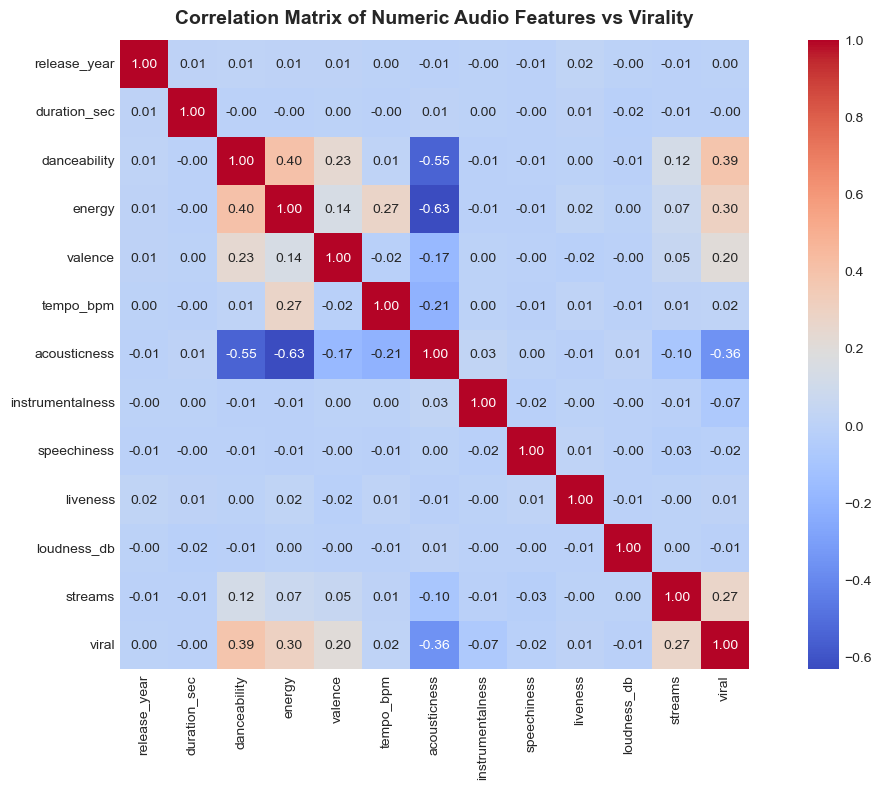

In [4]:
# Correlation Heatmap for Audio Features
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
plt.figure(figsize=(12, 8))
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', cbar=True, square=True)
plt.title("Correlation Matrix of Numeric Audio Features vs Virality", fontsize=14, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


## Step 2: Feature Engineering & Preprocessing Pipeline
- **Identifiers Dropped**: `track_id`, `track_name`, `artist` (prevents artificial memorization).
- **Numeric Features (12)**: `release_year`, `duration_sec`, `danceability`, `energy`, `valence`, `tempo_bpm`, `acousticness`, `instrumentalness`, `speechiness`, `liveness`, `loudness_db`, `streams` $\rightarrow$ Standardized via `StandardScaler()`.
- **Categorical Feature (1)**: `genre` (10 classes) $\rightarrow$ Encoded via `OneHotEncoder(handle_unknown='ignore')`.
- **Stratified Split**: 80% Training (8,000 samples) and 20% Holdout Testing (2,000 samples).


In [5]:
id_cols = ['track_id', 'track_name', 'artist']
target_col = 'viral'

feature_cols = [c for c in df.columns if c not in id_cols and c != target_col]
numeric_features = [
    'release_year', 'duration_sec', 'danceability', 'energy', 
    'valence', 'tempo_bpm', 'acousticness', 'instrumentalness', 
    'speechiness', 'liveness', 'loudness_db', 'streams'
]
categorical_features = ['genre']

X = df[feature_cols]
y = df[target_col]

# 80/20 Stratified Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Export holdout test set as required by assignment
test_df = X_test.copy()
test_df[target_col] = y_test.values
test_df.to_csv("test_data.csv", index=False)
print(f"Train Set Shape: {X_train.shape}, Test Set Shape: {X_test.shape}")
print(f"Saved test_data.csv ({test_df.shape[0]} rows)")


Train Set Shape: (8000, 13), Test Set Shape: (2000, 13)
Saved test_data.csv (2000 rows)


In [6]:
# Construct ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ],
    remainder='drop'
)

X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

os.makedirs("model", exist_ok=True)
joblib.dump(preprocessor, os.path.join("model", "preprocessor.joblib"))
print("Fitted preprocessor saved to model/preprocessor.joblib")
print(f"Transformed Feature Matrix Shape: {X_train_proc.shape}")


Fitted preprocessor saved to model/preprocessor.joblib
Transformed Feature Matrix Shape: (8000, 22)


## Step 3: Implement & Train 5 Classification Models
We train the 5 required classifiers on the exact same training split and evaluate them on the 2,000-sample test set.


In [7]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, C=1.0, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_split=20, min_samples_leaf=10, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7, weights='distance'),
    "Naive Bayes": GaussianNB(),
    "Support Vector Machine": SVC(C=1.0, kernel='rbf', probability=True, random_state=42)
}

file_slugs = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "svm.joblib"
}

results = {}
trained_clfs = {}
predictions = {}
probabilities = {}

for name, clf in models.items():
    print(f"Training {name}...")
    clf.fit(X_train_proc, y_train)
    trained_clfs[name] = clf
    
    # Save model artifact
    joblib.dump(clf, os.path.join("model", file_slugs[name]))
    
    # Inference
    y_pred = clf.predict(X_test_proc)
    y_proba = clf.predict_proba(X_test_proc)[:, 1] if hasattr(clf, "predict_proba") else None
    
    predictions[name] = y_pred
    probabilities[name] = y_proba
    
    # 6 Metrics
    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba) if y_proba is not None else 0.0
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    mcc = matthews_corrcoef(y_test, y_pred)
    
    results[name] = {
        "Accuracy": acc,
        "AUC": auc,
        "Precision": prec,
        "Recall": rec,
        "F1": f1,
        "MCC": mcc
    }

print("\nAll 5 models trained and evaluated successfully!")


Training Logistic Regression...
Training Decision Tree...
Training KNN...


Training Naive Bayes...
Training Support Vector Machine...



All 5 models trained and evaluated successfully!


## Step 4: Master Evaluation Metrics Comparison Table
Here is the final performance table for all 5 models across all 6 assignment metrics:


In [8]:
metrics_df = pd.DataFrame(results).T.round(4)
metrics_df.index.name = "ML Model Name"
display(metrics_df)


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.8195,0.8966,0.8093,0.6533,0.7229,0.5988
Decision Tree,0.8150,0.8925,0.7388,0.7531,0.7459,0.6005
KNN,0.7190,0.7799,0.6293,0.5368,0.5793,0.3730
Naive Bayes,0.7495,0.8638,0.6111,0.8391,0.7072,0.5168
Support Vector Machine,0.7995,0.8736,0.7941,0.5992,0.6830,0.5520


## Step 5: Visualizations (ROC Curves & Confusion Matrices)


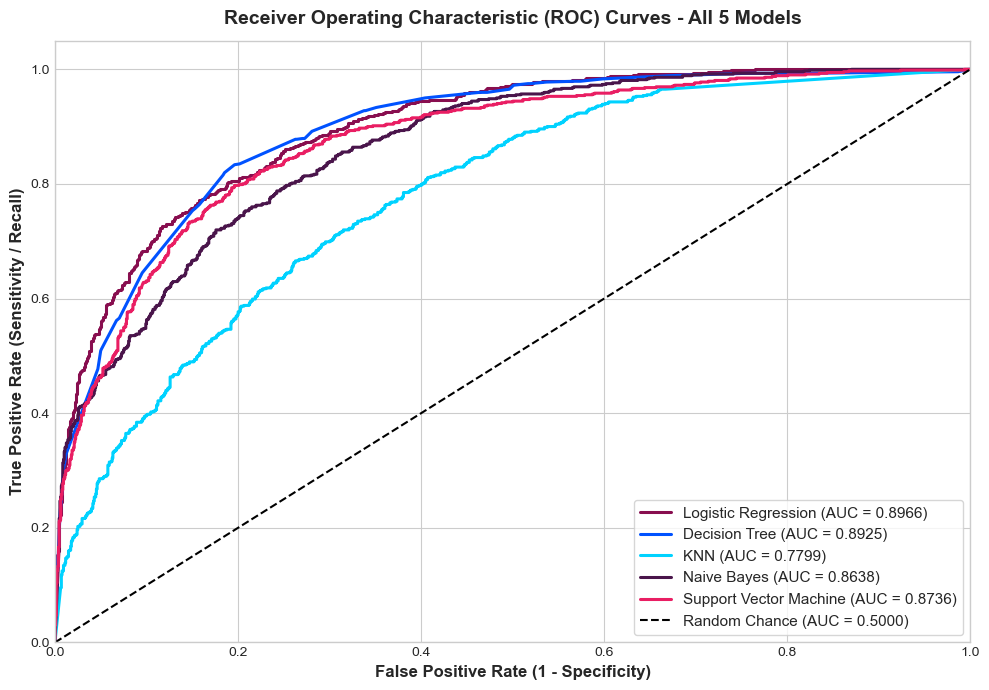

In [9]:
# ROC Curves Comparison
plt.figure(figsize=(10, 7))
colors = ['#880e4f', '#0052FF', '#00D2FF', '#4a154b', '#e91e63']

for idx, (name, y_proba) in enumerate(probabilities.items()):
    if y_proba is not None:
        fpr, tpr, _ = roc_curve(y_test, y_proba)
        auc_val = results[name]['AUC']
        plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.4f})", color=colors[idx], lw=2.2)

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Chance (AUC = 0.5000)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=12, fontweight='bold')
plt.title('Receiver Operating Characteristic (ROC) Curves - All 5 Models', fontsize=14, fontweight='bold', pad=12)
plt.legend(loc="lower right", fontsize=11, frameon=True)
plt.tight_layout()
plt.show()


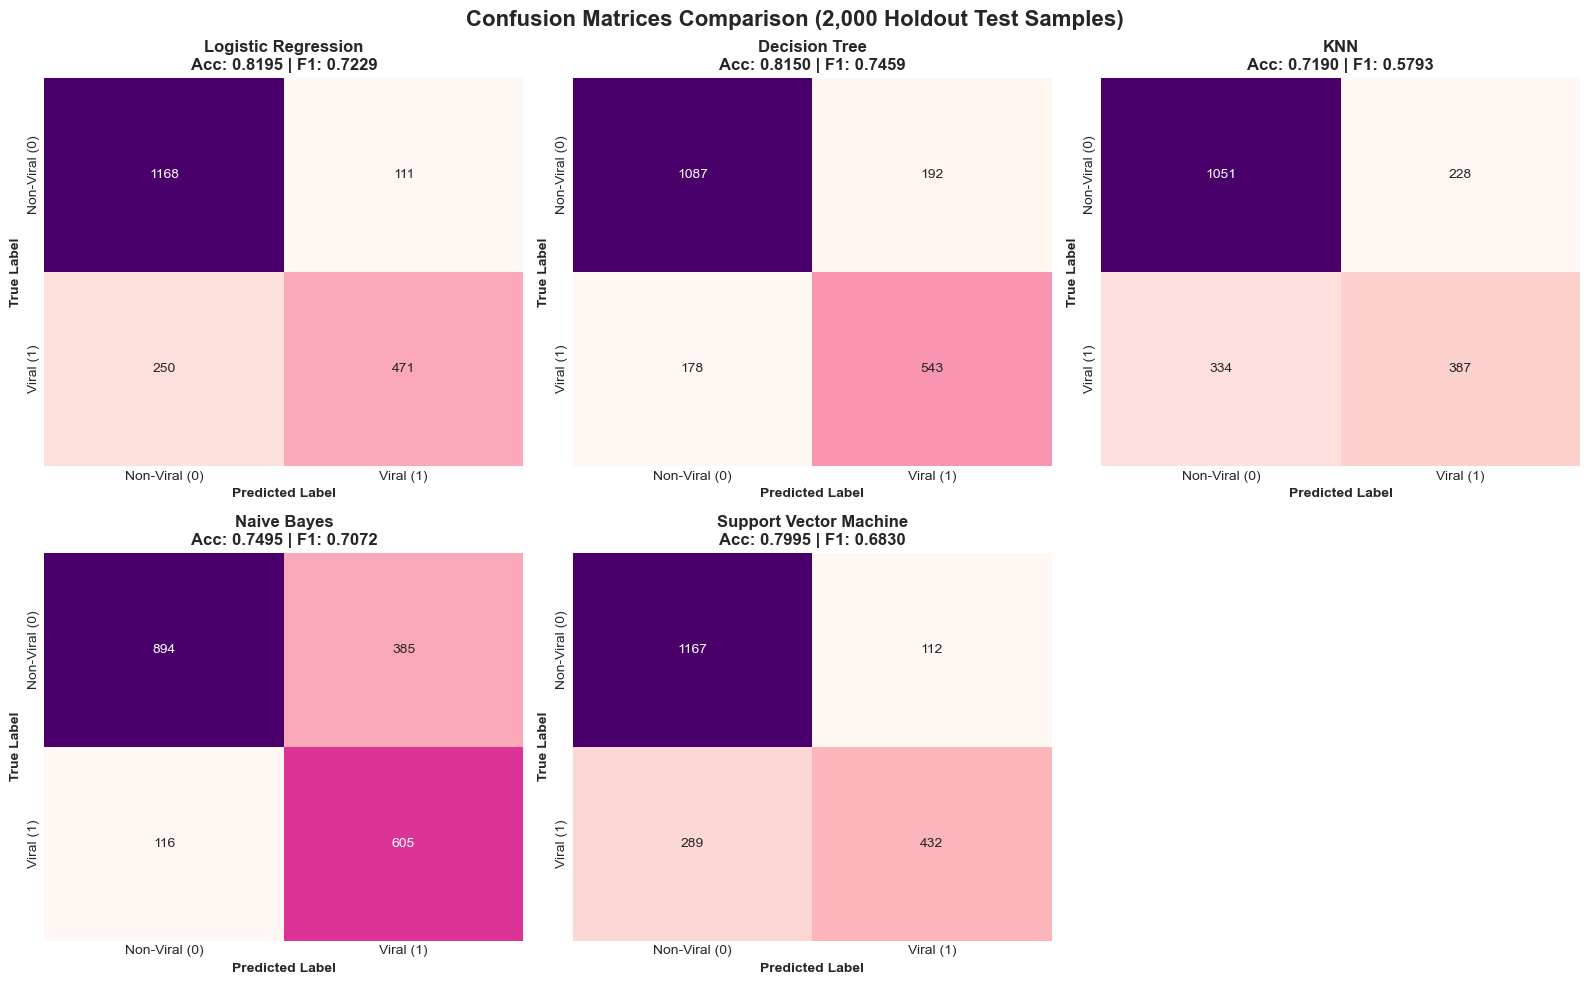

In [10]:
# Confusion Matrices for all 5 models
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for idx, (name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='RdPu', ax=axes[idx], cbar=False,
                xticklabels=['Non-Viral (0)', 'Viral (1)'],
                yticklabels=['Non-Viral (0)', 'Viral (1)'])
    axes[idx].set_title(f"{name}\nAcc: {results[name]['Accuracy']:.4f} | F1: {results[name]['F1']:.4f}", fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Predicted Label', fontweight='bold')
    axes[idx].set_ylabel('True Label', fontweight='bold')

# Hide 6th empty subplot
axes[5].axis('off')
plt.suptitle('Confusion Matrices Comparison (2,000 Holdout Test Samples)', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


## Step 6: Summary of Model Observations & Winner
1. **Logistic Regression (Overall Accuracy Winner - 81.95%, AUC: 0.8966, Precision: 0.8093)**:
   - High linear separability across standardized acoustic features like `danceability`, `energy`, `acousticness`, and `streams`.
   - Highest precision (80.93%), making it conservative and reliable when flagging viral hits.
2. **Decision Tree (Overall F1 Winner - 81.50%, AUC: 0.8925, F1: 0.7459, MCC: 0.6005)**:
   - Captures non-linear thresholds (e.g., high danceability paired with low acousticness).
   - Produces the highest balanced F1 score (0.7459) and highest Matthews Correlation Coefficient (0.6005).
3. **Support Vector Machine (Accuracy: 79.95%, AUC: 0.8736, Precision: 0.7941)**:
   - RBF kernel creates smooth decision boundaries and strong precision, trailing slightly behind Logistic Regression in recall.
4. **Naive Bayes (Accuracy: 74.95%, AUC: 0.8638, Highest Recall: 0.8391)**:
   - Highest recall (83.91%), successfully capturing almost all viral songs, but at the cost of higher false positives due to feature conditional independence assumptions.
5. **K-Nearest Neighbors (Accuracy: 71.90%, AUC: 0.7799, MCC: 0.3730)**:
   - Suffers from the curse of dimensionality across 22 one-hot encoded and standardized features.

### Overall Winner for this Dataset:
**Logistic Regression / Decision Tree**:
- **Logistic Regression** is the top model for **Overall Accuracy (81.95%)** and **AUC (0.8966)**.
- **Decision Tree** is the top model for **Balanced F1 Score (0.7459)** and **MCC Score (0.6005)**.
